# Profile eCHORD z master patternu EMsoft — wykresy

Notebook pokazuje, co liczy `echord_cone.py` na prawdziwym masterze:

1. podgląd master patternu (Lambert i rzut stereograficzny) i test konwencji,
2. wczytanie orientacji z pliku kątów `test_ang_quaterion.csv`,
3. ścieżkę stożka na masterze i odpowiadający jej profil $I(\omega)$,
4. profile dla wielu orientacji,
5. wpływ parametrów: `sense`, `phi0`, `invert`, zbieżność wiązki, interpolacja, kąt pochyłu,
6. jak szybko profil zmienia się z dezorientacją (ważne dla skali długości GP),
7. *(opcjonalnie)* profile eksperymentalne z `.tif` i kalibrację `phi0`, `sense`.

Notebook trzymaj w tym samym folderze co `echord_cone.py` (Jupyter importuje moduły z folderu notebooka). Ścieżki do danych ustawiasz w pierwszej komórce.

In [ ]:
import os

import numpy as np
import matplotlib.pyplot as plt

import echord_cone as ec

DATA_DIR = "/home/pz/workspace/agh/gaussian/2026_10_19_example_PZ"
MASTER_PATH = os.path.join(DATA_DIR, "masterKTN_014_01.h5")
CSV_PATH = os.path.join(DATA_DIR, "test_ang_quaterion.csv")
TIF_PATH = os.path.join(DATA_DIR, "KTN_014_s2_fin_crop_372x372_bin_62x62.tif")

coneAngle = 40      # pochył próbki [deg]
angleStep = 2       # krok obrotu [deg]
phi0, sense = 0.0, +1   # na razie nieznane, patrz sekcja 7

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(0)

### Funkcje pomocnicze

In [ ]:
def zscore(p, axis=-1):
    # średnia 0, odchylenie 1 wzdłuż osi omega (tak porównuje się profile)
    p = np.asarray(p, dtype=float)
    return (p - p.mean(axis, keepdims=True)) / p.std(axis, keepdims=True)


def to_stereo(d):
    # kierunki (...,3) -> współrzędne stereograficzne (...,2) + maska półkuli N
    d = d / np.linalg.norm(d, axis=-1, keepdims=True)
    north = d[..., 2] >= 0
    return d[..., :2] / (1 + np.abs(d[..., 2]))[..., None], north


def stereo_image(mp, n=401, north=True):
    # rzut stereograficzny półkuli odtworzony przez mp.lookup (poza dyskiem NaN)
    g = np.linspace(-1, 1, n)
    XX, YY = np.meshgrid(g, g)
    d = ec.stereo_to_sphere(np.stack([XX, YY], -1))
    if not north:
        d[..., 2] *= -1
    img = mp.lookup(d)
    img[XX**2 + YY**2 > 1] = np.nan
    return img


def show(ax, img, extent=(-1, 1, -1, 1), title=""):
    lo, hi = np.nanpercentile(img, [1, 99])
    ax.imshow(img, origin="lower", extent=extent, cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.grid(False)


def axis_angle_matrix(axes, angle_deg):
    # aktywne obroty o kąt wokół osi (N,3) — wzór Rodriguesa, wynik (N,3,3)
    axes = axes / np.linalg.norm(axes, axis=1, keepdims=True)
    a = np.deg2rad(angle_deg)
    K = np.zeros((axes.shape[0], 3, 3))
    K[:, 0, 1], K[:, 0, 2], K[:, 1, 2] = -axes[:, 2], axes[:, 1], -axes[:, 0]
    K -= K.transpose(0, 2, 1)
    return np.eye(3) + np.sin(a) * K + (1 - np.cos(a)) * K @ K


def random_matrices(rng, n):
    # orientacje jednorodne na SO(3)
    e = np.column_stack([rng.uniform(0, 360, n),
                         np.rad2deg(np.arccos(rng.uniform(-1, 1, n))),
                         rng.uniform(0, 360, n)])
    return ec.bunge_to_matrix(e)

## 1. Master pattern i test konwencji

`validate_with_stereo()` porównuje nasz odczyt z rzutem stereograficznym `masterSPNH`, który policzył sam EMsoft. Wariant `transpose=False flip_x=False flip_y=False` powinien mieć r ≈ 1 i być na górze (przy wysokiej symetrii kilka wariantów może remisować — to wtedy nieistotne).

In [ ]:
mp = ec.MasterPattern(MASTER_PATH, energy="max")
print(mp)
print()
_ = mp.validate_with_stereo()

MasterPattern('/home/pz/workspace/agh/gaussian/2026_10_19_example_PZ/masterKTN_014_01.h5')
  dataset : EMData/ECPmaster/mLPNH, surowy kształt (4, 1025, 1025)
  npx     : 512  (obraz 1025^2)
  energie : brak, wybór: max
  accum_e : nie, masterSPNH: tak
  kryształ: grupa przestrzenna 99, centrosymetryczna: False, parametry sieci: [ 0.39930001  0.39930001  0.40019998 90.         90.         90.        ]

  transpose=False flip_x=False flip_y=False  r = 1.00000
  transpose=False flip_x=False flip_y=True   r = 1.00000
  transpose=False flip_x=True  flip_y=False  r = 1.00000
  transpose=False flip_x=True  flip_y=True   r = 1.00000
  transpose=True  flip_x=False flip_y=False  r = 1.00000
  transpose=True  flip_x=False flip_y=True   r = 1.00000
  transpose=True  flip_x=True  flip_y=False  r = 1.00000
  transpose=True  flip_x=True  flip_y=True   r = 1.00000


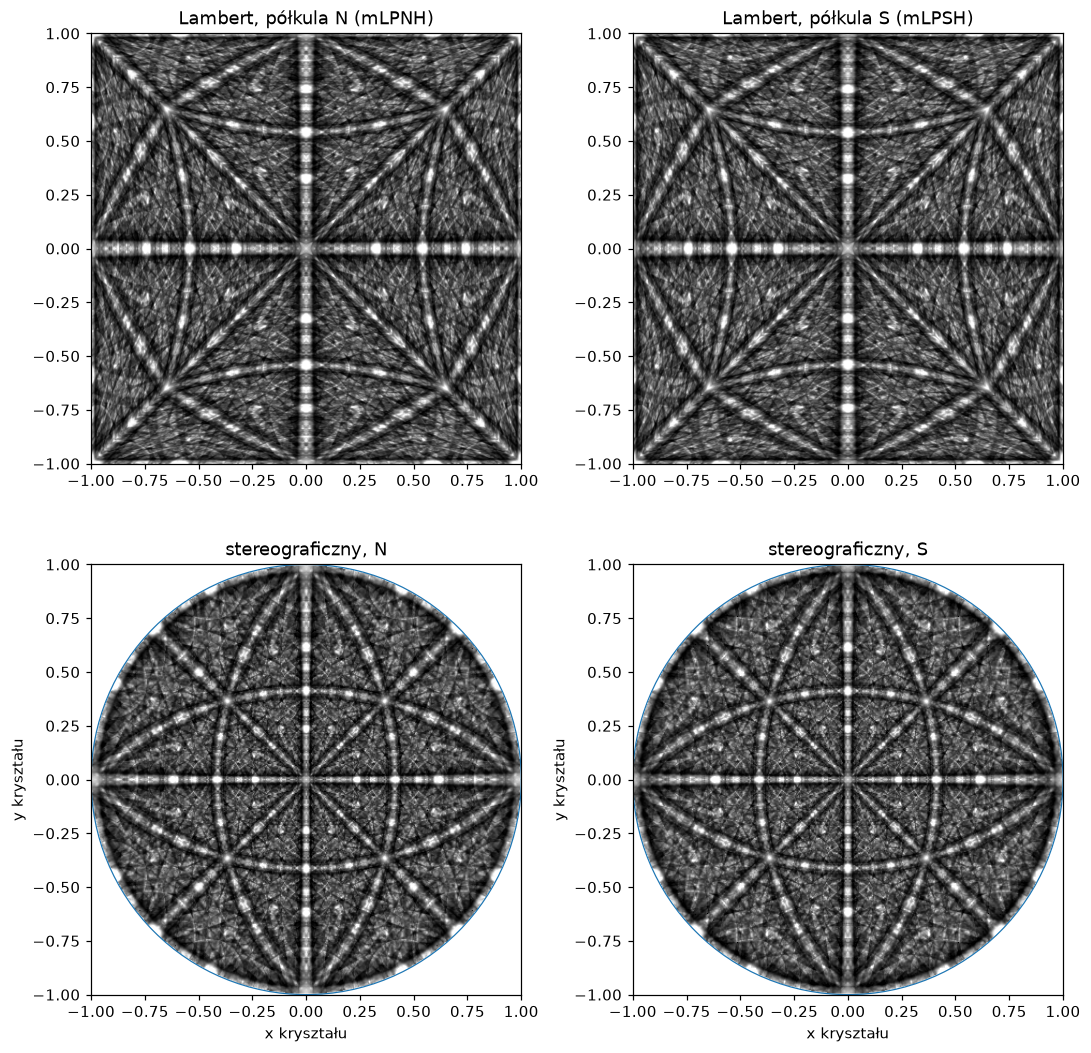

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(10, 10))
show(ax[0, 0], mp.NH, title="Lambert, półkula N (mLPNH)")
show(ax[0, 1], mp.SH, title="Lambert, półkula S (mLPSH)")
show(ax[1, 0], stereo_image(mp, north=True), title="stereograficzny, N")
show(ax[1, 1], stereo_image(mp, north=False), title="stereograficzny, S")
for a in ax[1]:
    a.add_patch(plt.Circle((0, 0), 1, fill=False, color="tab:blue", lw=0.8))
    a.set_xlabel("x kryształu")
    a.set_ylabel("y kryształu")
fig.tight_layout()

## 2. Orientacje z pliku kątów

`test_ang_quaterion.csv` to mimo rozszerzenia plik kątów w formacie EMsoftu: pierwsza linia to typ (`qu` albo `eu`), druga to liczba orientacji, dalej po jednej orientacji w wierszu. Taki format daje np. EMsampleRFZ, więc to raczej próbkowanie przestrzeni orientacji niż orientacje kolejnych pikseli mapy.

In [ ]:
rep, ori = ec.read_anglefile(CSV_PATH)
print(f"typ: {rep}, kształt: {ori.shape}")
print("pierwsze wiersze:\n", ori[:3])

if rep == "quat":
    norms = np.linalg.norm(ori, axis=1)
    print(f"\nnorma: min {norms.min():.6f}, max {norms.max():.6f}")
    print(f"udział q0 >= 0: {np.mean(ori[:, 0] >= 0):.2f}  (konwencja EMsoftu: 1.00)")

G = ec.to_matrices(ori, rep=rep)
print("liczba orientacji:", len(G))

typ: quat, kształt: (9077, 4)
pierwsze wiersze:
 [[ 0.8562438  -0.34742655 -0.34742655 -0.15948713]
 [ 0.8562438  -0.35279671 -0.35279671 -0.13384887]
 [ 0.8562438  -0.35279671 -0.35279671  0.13384887]]

norma: min 1.000000, max 1.000000
udział q0 >= 0: 1.00  (konwencja EMsoftu: 1.00)
liczba orientacji: 9077


## 3. Ścieżka stożka na masterze i profil

Kolor punktów na ścieżce odpowiada kątowi obrotu ω (paleta cykliczna), ten sam kolor jest na profilu po prawej — tak widać, które pasmo Kikuchiego daje który pik. Pomarańczowe kółko to ω = 0.

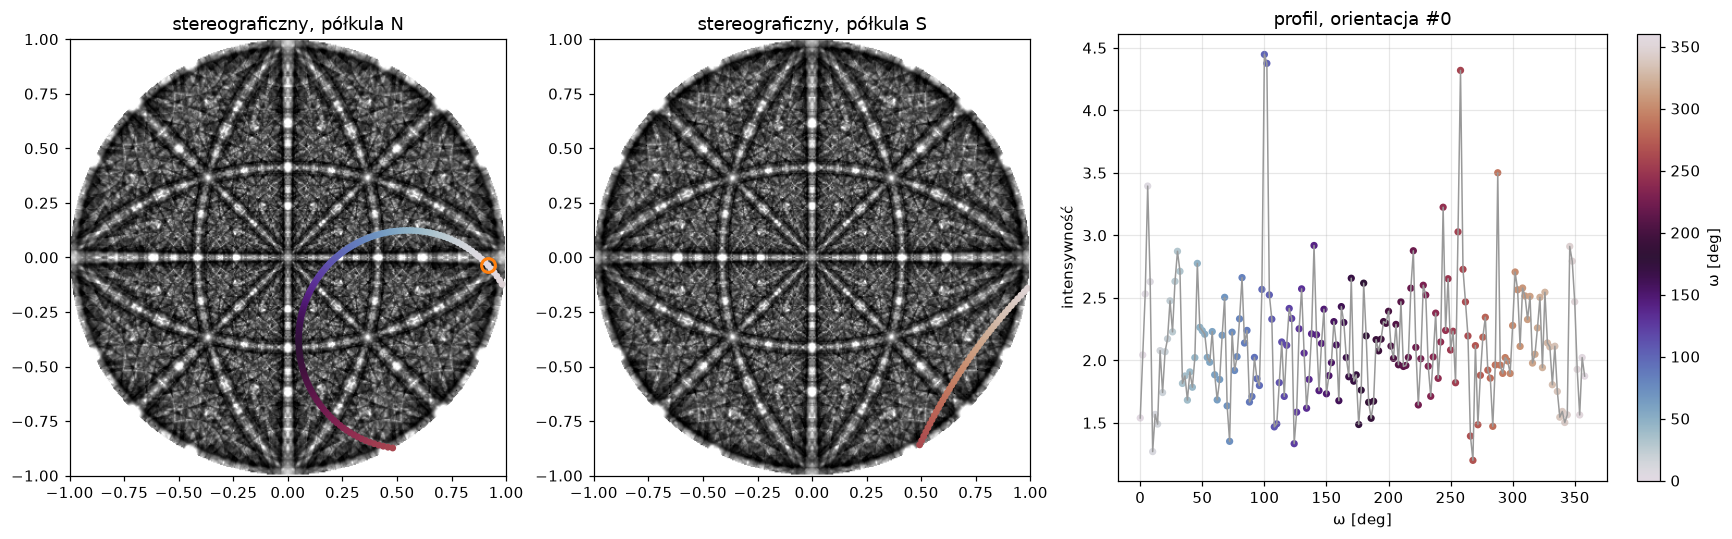

In [ ]:
IDX = 0                                    # która orientacja z pliku kątów
omega, prof = mp.cone_profiles(G[IDX:IDX + 1], coneAngle, angleStep,
                               phi0=phi0, sense=sense, rep="matrix")
path = mp.cone_path_crystal(G[IDX:IDX + 1], coneAngle, angleStep,
                            phi0=phi0, sense=sense, rep="matrix")
xy, north = to_stereo(path)

fig, ax = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1, 1.4]})
for a, hemi, mask, name in ((ax[0], True, north, "N"), (ax[1], False, ~north, "S")):
    show(a, stereo_image(mp, north=hemi), title=f"stereograficzny, półkula {name}")
    a.scatter(xy[mask, 0], xy[mask, 1], c=omega[mask], cmap="twilight", vmin=0, vmax=360, s=12)
    if mask[0]:
        a.plot(*xy[0], "o", ms=9, mfc="none", mec="tab:orange", mew=2)
ax[2].plot(omega, prof[0], color="0.6", lw=1)
sc = ax[2].scatter(omega, prof[0], c=omega, cmap="twilight", vmin=0, vmax=360, s=14)
ax[2].set_xlabel("ω [deg]")
ax[2].set_ylabel("intensywność")
ax[2].set_title(f"profil, orientacja #{IDX}")
fig.colorbar(sc, ax=ax[2], label="ω [deg]")
fig.tight_layout()

### Rozdzielczość próbkowania

Przy pochyle 40° kolejne punkty pomiaru dzieli na sferze łuk ≈ Δω·sin θ. Poniżej profil liczony co 0,1° (szary) i w punktach pomiaru (czerwony): wąskie struktury między punktami pomiaru są niewidoczne w danych, ale zmieniają się przy małej zmianie orientacji.

łuk między punktami pomiaru: 1.29 deg


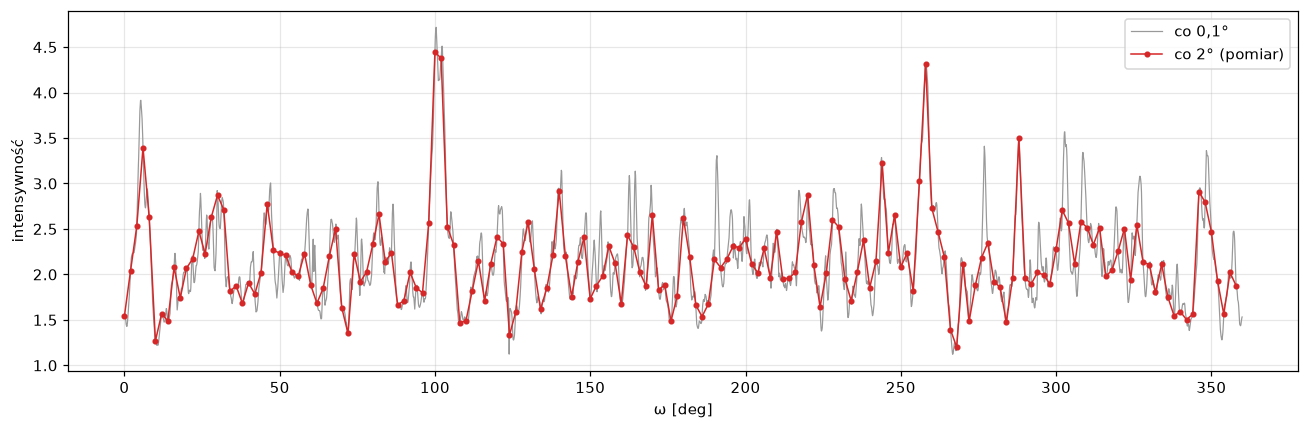

In [ ]:
om_fine, p_fine = mp.cone_profiles(G[IDX:IDX + 1], coneAngle, 0.1, phi0=phi0, sense=sense, rep="matrix")
print(f"łuk między punktami pomiaru: {angleStep * np.sin(np.deg2rad(coneAngle)):.2f} deg")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(om_fine, p_fine[0], color="0.6", lw=0.8, label="co 0,1°")
ax.plot(omega, prof[0], "o-", ms=3, color="tab:red", lw=1, label=f"co {angleStep}° (pomiar)")
ax.set_xlabel("ω [deg]")
ax.set_ylabel("intensywność")
ax.legend()
fig.tight_layout()

## 4. Profile dla wielu orientacji

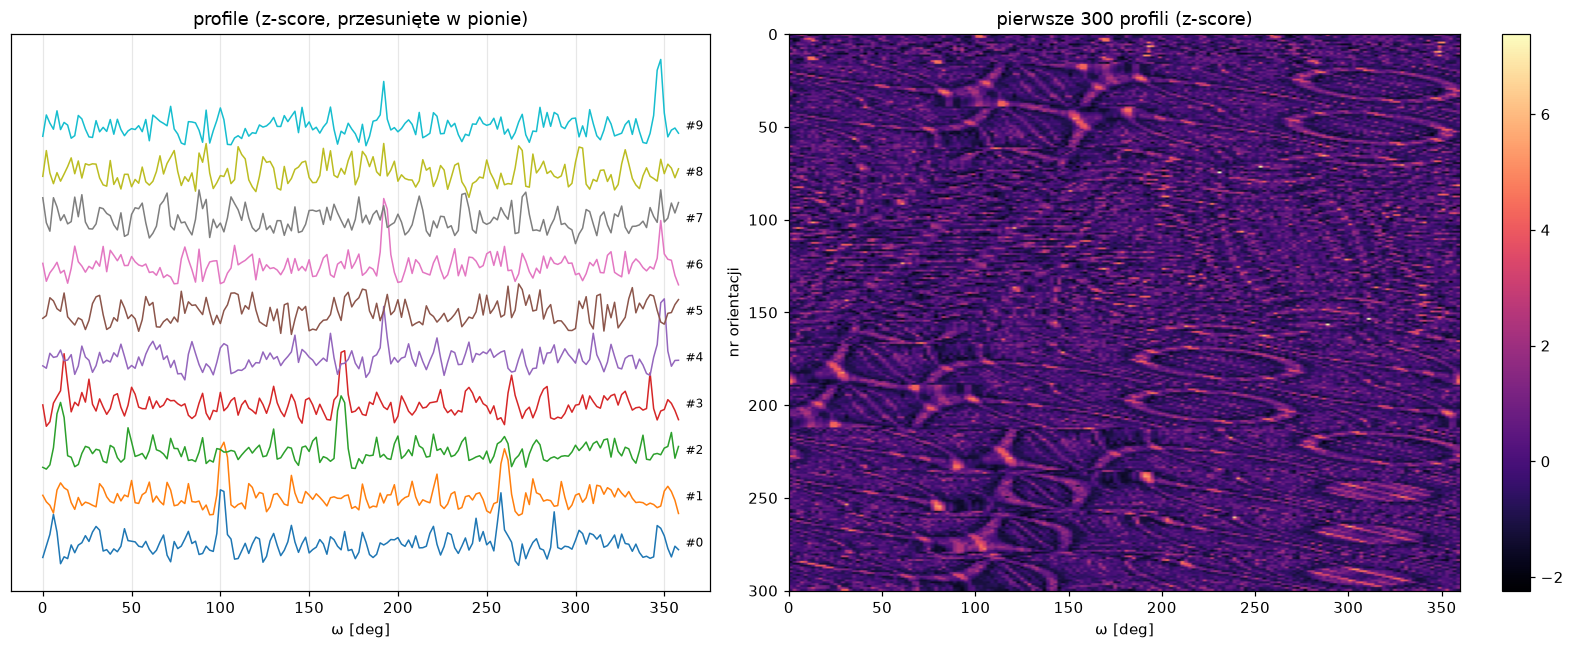

In [ ]:
_, P = mp.cone_profiles(G, coneAngle, angleStep, phi0=phi0, sense=sense, rep="matrix")
Pz = zscore(P)

n_show = min(10, len(Pz))
fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.2]})
for k in range(n_show):
    ax[0].plot(omega, Pz[k] + 4 * k, lw=1)
    ax[0].text(362, 4 * k, f"#{k}", va="center", fontsize=8)
ax[0].set_xlabel("ω [deg]")
ax[0].set_yticks([])
ax[0].set_title("profile (z-score, przesunięte w pionie)")

n_map = min(300, len(Pz))
im = ax[1].imshow(Pz[:n_map], aspect="auto", cmap="magma",
                  extent=(omega[0], omega[-1] + angleStep, n_map, 0))
ax[1].set_xlabel("ω [deg]")
ax[1].set_ylabel("nr orientacji")
ax[1].set_title(f"pierwsze {n_map} profili (z-score)")
ax[1].grid(False)
fig.colorbar(im, ax=ax[1])
fig.tight_layout()

## 5. Wpływ parametrów

* **sense** — kierunek obrotu stolika: profil odbity w ω,
* **phi0** — azymut pochyłu: czyste cykliczne przesunięcie (tak samo działa φ1),
* **invert** — d czy −d; różnica tylko dla faz bez środka symetrii,
* **zbieżność wiązki** σ — rozmycie gaussowskie,
* **interpolacja** — dwuliniowa (jak EMsoft) czy splajn kubiczny,
* **kąt pochyłu** — niepewność ±1° (Lafond zauważył, że rzeczywisty kąt odbiega od nominalnego).

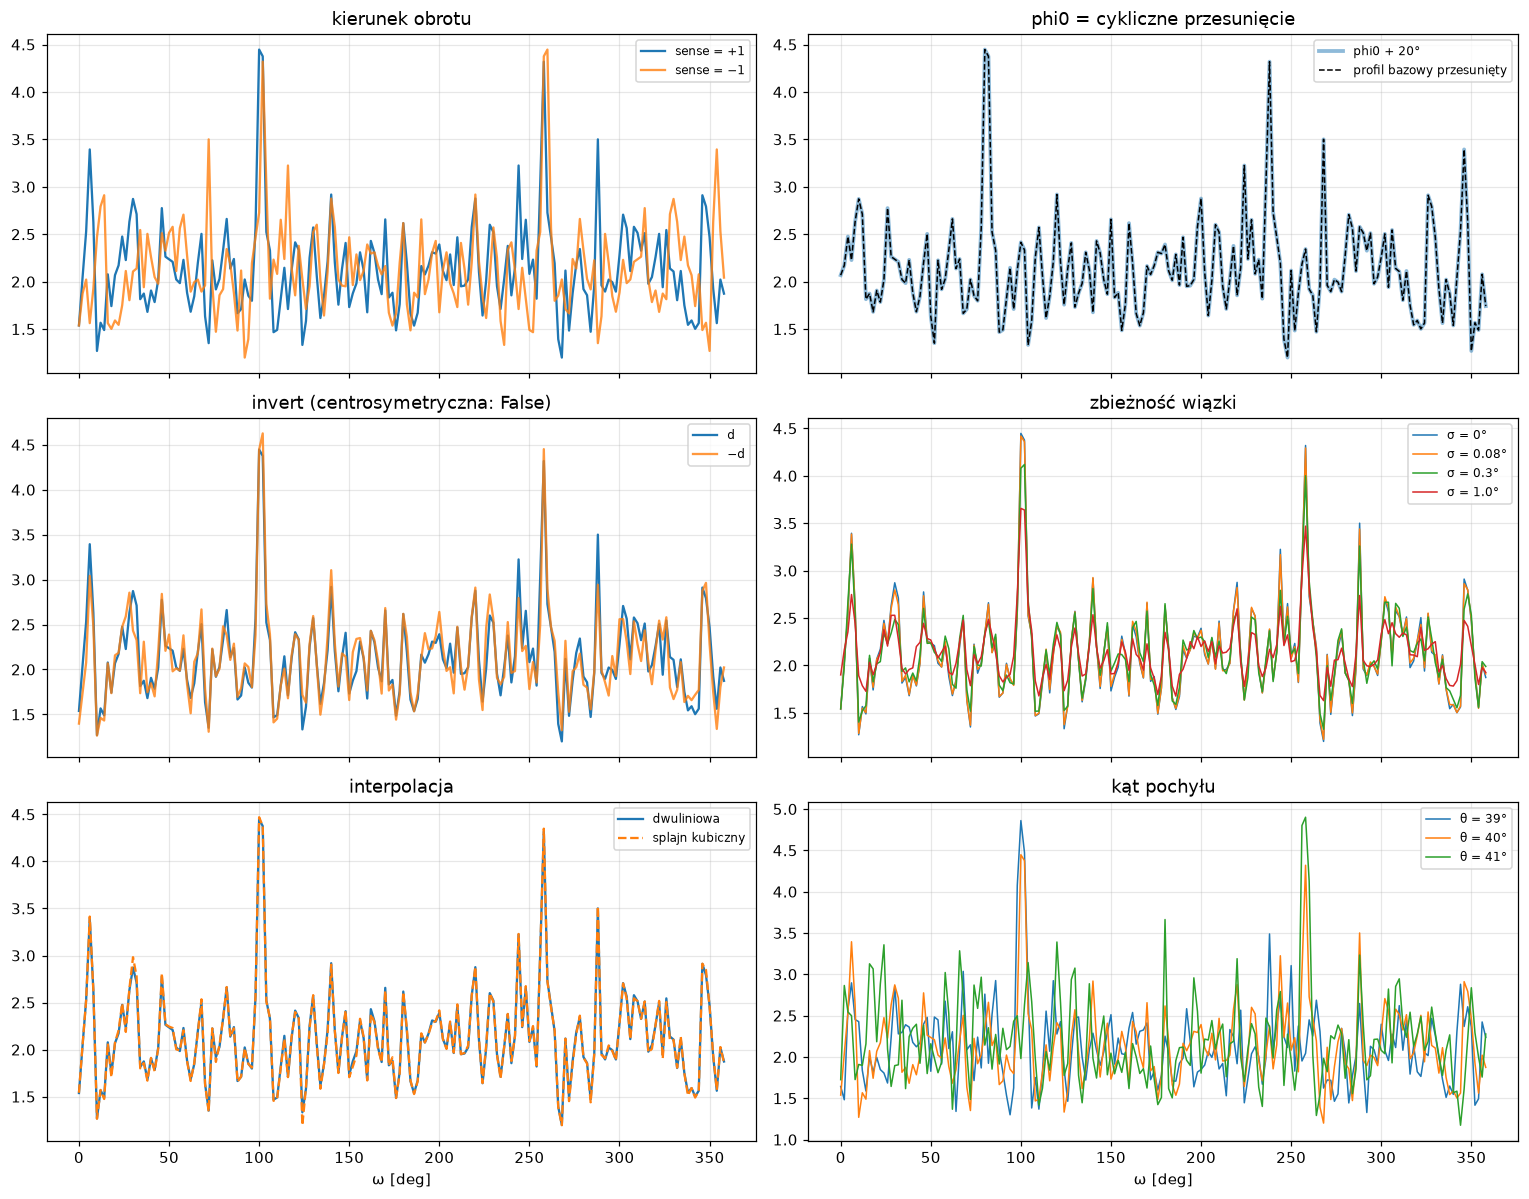

In [ ]:
g0 = G[IDX:IDX + 1]
kw = dict(rep="matrix")


def cp(cone=coneAngle, **extra):
    # profil orientacji #IDX; domyślne parametry z góry notebooka, extra je nadpisuje
    opts = dict(phi0=phi0, sense=sense, rep="matrix")
    opts.update(extra)
    return mp.cone_profiles(g0, cone, angleStep, **opts)[1][0]


fig, ax = plt.subplots(3, 2, figsize=(14, 11), sharex=True)
ax = ax.ravel()

ax[0].plot(omega, cp(sense=+1), label="sense = +1")
ax[0].plot(omega, cp(sense=-1), label="sense = −1", alpha=0.8)
ax[0].set_title("kierunek obrotu")

shift = 20
ax[1].plot(omega, cp(phi0=phi0 + shift), lw=2.5, alpha=0.5, label=f"phi0 + {shift}°")
ax[1].plot(omega, np.roll(cp(), -int(sense * shift / angleStep)), "k--", lw=1,
           label="profil bazowy przesunięty")
ax[1].set_title("phi0 = cykliczne przesunięcie")

ax[2].plot(omega, cp(), label="d")
ax[2].plot(omega, cp(invert=True), alpha=0.8, label="−d")
ax[2].set_title(f"invert (centrosymetryczna: {mp.centrosymmetric})")

for s in (0, 0.08, 0.3, 1.0):
    ax[3].plot(omega, cp(sigma_conv_deg=s), lw=1, label=f"σ = {s}°")
ax[3].set_title("zbieżność wiązki")

mp3 = ec.MasterPattern(MASTER_PATH, energy=mp.energy, order=3)
ax[4].plot(omega, cp(), label="dwuliniowa")
ax[4].plot(omega, mp3.cone_profiles(g0, coneAngle, angleStep, phi0=phi0, sense=sense, **kw)[1][0],
           "--", label="splajn kubiczny")
ax[4].set_title("interpolacja")

for c in (coneAngle - 1, coneAngle, coneAngle + 1):
    ax[5].plot(omega, cp(cone=c), lw=1, label=f"θ = {c}°")
ax[5].set_title("kąt pochyłu")

for a in ax:
    a.legend(fontsize=8)
for a in ax[-2:]:
    a.set_xlabel("ω [deg]")
fig.tight_layout()

Jeśli master ma kilka kanałów energii (EBSD z Monte Carlo), porównanie kanału energii wiązki z uśrednieniem ważonym histogramem energii:

In [ ]:
if mp.ekevs is not None and mp.ekevs.size > 1:
    mpw = ec.MasterPattern(MASTER_PATH, energy="weighted")
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(omega, zscore(cp()), label=f"energy='max' ({mp.ekevs.max():.1f} keV)")
    ax.plot(omega, zscore(mpw.cone_profiles(g0, coneAngle, angleStep, phi0=phi0,
                                            sense=sense, **kw)[1][0]), label="energy='weighted'")
    ax.set_xlabel("ω [deg]")
    ax.set_ylabel("z-score")
    ax.legend()
    fig.tight_layout()
else:
    print("Master bez osi energii (np. ECP) — porównanie pominięte.")

Master bez osi energii (np. ECP) — porównanie pominięte.


## 6. Jak szybko profil zmienia się z orientacją

Dla losowych orientacji obracamy kryształ o mały kąt δ wokół losowej osi i liczymy korelację profilu przed i po. Kąt, przy którym mediana korelacji spada np. do 0,5, to rząd wielkości skali długości, jakiej GP potrzebowałby w przestrzeni orientacji.

mediana korelacji spada do 0.5 przy δ ≈ 1.38°


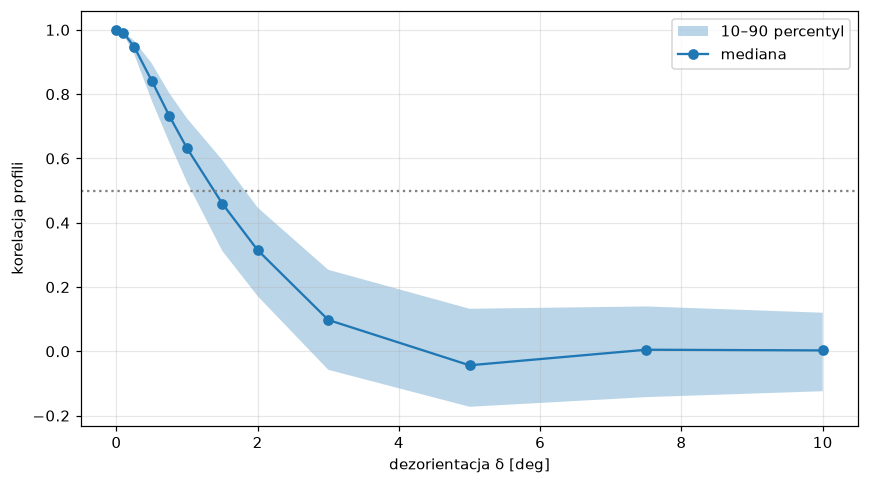

In [ ]:
N_ORI = 300
deltas = np.array([0, 0.1, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 5, 7.5, 10])
Gr = random_matrices(rng, N_ORI)
_, p_ref = mp.cone_profiles(Gr, coneAngle, angleStep, rep="matrix")
zr = zscore(p_ref)

corr = np.empty((deltas.size, N_ORI))
for i, d in enumerate(deltas):
    R = axis_angle_matrix(rng.normal(size=(N_ORI, 3)), d)
    _, p_rot = mp.cone_profiles(R @ Gr, coneAngle, angleStep, rep="matrix")
    corr[i] = np.mean(zr * zscore(p_rot), axis=1)

med = np.median(corr, axis=1)
lo, hi = np.percentile(corr, [10, 90], axis=1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between(deltas, lo, hi, alpha=0.3, label="10–90 percentyl")
ax.plot(deltas, med, "o-", label="mediana")
ax.axhline(0.5, color="0.5", ls=":")
ax.set_xlabel("dezorientacja δ [deg]")
ax.set_ylabel("korelacja profili")
ax.legend()
fig.tight_layout()
if med.min() < 0.5:
    print(f"mediana korelacji spada do 0.5 przy δ ≈ {np.interp(0.5, med[::-1], deltas[::-1]):.2f}°")
else:
    print(f"mediana nie spada do 0.5 do δ = {deltas[-1]}° — rozszerz deltas")

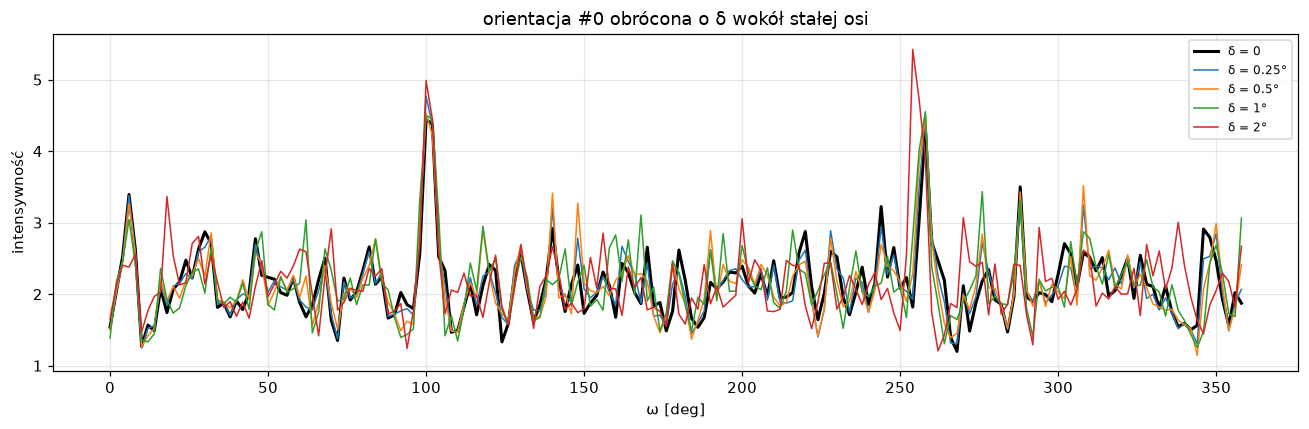

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(omega, cp(), "k", lw=2, label="δ = 0")
for d in (0.25, 0.5, 1, 2):
    R = axis_angle_matrix(np.array([[1.0, 1.0, 0.3]]), d)
    ax.plot(omega, mp.cone_profiles(R @ g0, coneAngle, angleStep, phi0=phi0,
                                    sense=sense, rep="matrix")[1][0], lw=1, label=f"δ = {d}°")
ax.set_xlabel("ω [deg]")
ax.set_ylabel("intensywność")
ax.set_title(f"orientacja #{IDX} obrócona o δ wokół stałej osi")
ax.legend(fontsize=8)
fig.tight_layout()

## 7. *(Opcjonalnie)* Dane eksperymentalne i kalibracja `phi0`, `sense`

Wymaga pakietu `tifffile` (`pip install tifffile`). Komórka szuka w stosie osi z liczbą klatek równą 360/Δω (lub +1) i pokazuje profile kilku pikseli.

Kalibracja potrzebuje **orientacji kolejnych pikseli mapy** (np. wyniku metody słownikowej): wiersz `r` pliku kątów ma odpowiadać pikselowi `(r // nx, r % nx)`. Próbkowanie przestrzeni orientacji (EMsampleRFZ) się do tego nie nadaje — wtedy kalibracja zostanie pominięta. Ustaw `MAP_ANGLES` na plik z orientacjami pikseli, gdy go będziesz mieć. Wtedy dla losowych pikseli liczymy korelację profilu eksperymentalnego z symulowanym przy wszystkich przesunięciach cyklicznych i obu wartościach `sense`. Przed porównaniem z obu usuwamy najniższe harmoniki w ω, bo detektor BSE przy pochylonej próbce daje gładkie tło zależne od obrotu.

stos: 180 klatek, 62 x 62 pikseli (oczekiwane klatki: 180)


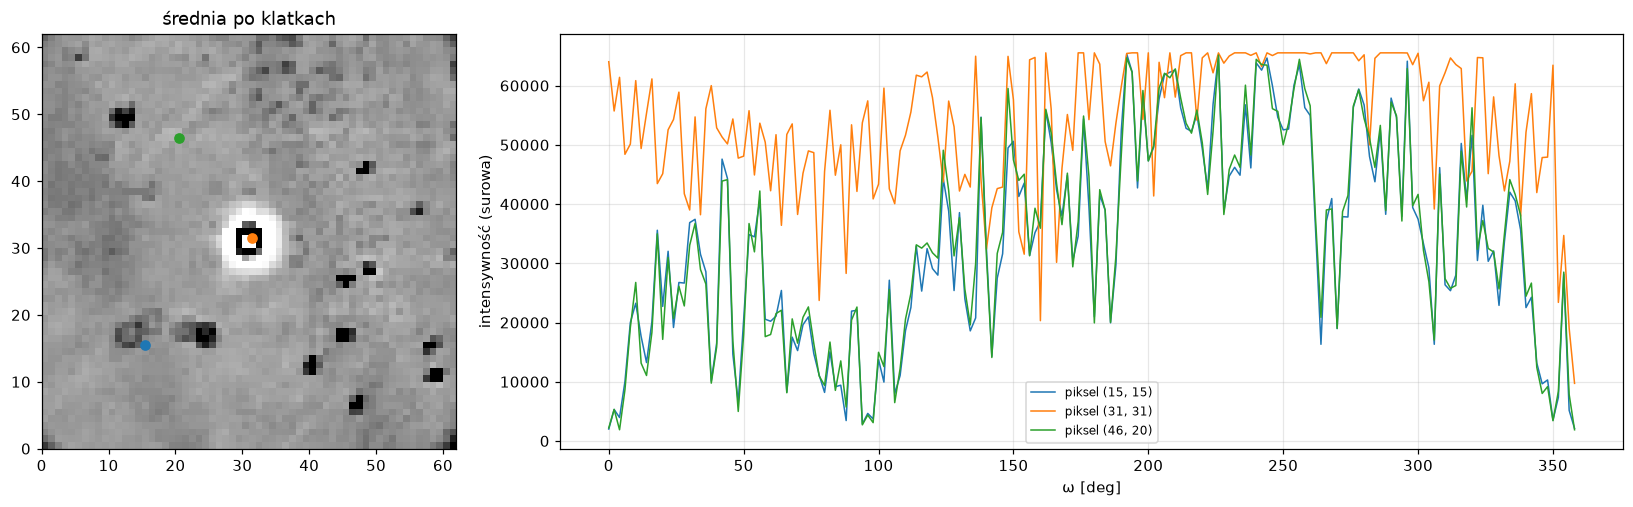

In [ ]:
try:
    import tifffile
    stack = tifffile.imread(TIF_PATH).astype(float)
except Exception as err:
    stack = None
    print("Pomijam sekcję 7:", err)

if stack is not None:
    n_exp = int(round(360 / angleStep))
    ax_f = next((i for i, n in enumerate(stack.shape) if n in (n_exp, n_exp + 1)), 0)
    stack = np.moveaxis(stack, ax_f, 0)
    if stack.shape[0] == n_exp + 1:
        print("Klatki 0° i 360° zdublowane — odrzucam ostatnią.")
        stack = stack[:-1]
    M, ny, nx = stack.shape
    print(f"stos: {M} klatek, {ny} x {nx} pikseli (oczekiwane klatki: {n_exp})")

    om_exp = np.arange(M) * 360 / M
    pix = [(ny // 4, nx // 4), (ny // 2, nx // 2), (3 * ny // 4, nx // 3)]
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 2.5]})
    show(ax[0], stack.mean(0), extent=(0, nx, 0, ny), title="średnia po klatkach")
    for (iy, ix) in pix:
        ax[0].plot(ix + 0.5, iy + 0.5, "o", ms=6)
        ax[1].plot(om_exp, stack[:, iy, ix], lw=1, label=f"piksel ({iy}, {ix})")
    ax[1].set_xlabel("ω [deg]")
    ax[1].set_ylabel("intensywność (surowa)")
    ax[1].legend(fontsize=8)
    fig.tight_layout()

In [ ]:
MAP_ANGLES = CSV_PATH   # <- plik kątów z orientacjami PIKSELI (kolejność wierszami)
N_HARM = 2      # ile najniższych harmonik w ω usuwamy (tło detektora); 0 = tylko średnia
N_PIX = 200     # ile losowych pikseli do kalibracji

rep_map, ori_map = ec.read_anglefile(MAP_ANGLES)
Gmap = ec.to_matrices(ori_map, rep=rep_map)


def detrend(p, n=N_HARM):
    F = np.fft.rfft(p, axis=-1)
    F[..., : n + 1] = 0
    return zscore(np.fft.irfft(F, n=p.shape[-1], axis=-1))


def circ_corr(a, b):
    # c[k] = mean_j a[j] * b[j - k]  (= korelacja a z np.roll(b, k)), dla wszystkich k
    return np.fft.irfft(np.fft.rfft(a) * np.conj(np.fft.rfft(b)), n=a.shape[-1]) / a.shape[-1]


if stack is None:
    print("Brak stosu eksperymentalnego — pomijam kalibrację.")
elif len(Gmap) != ny * nx or M != omega.size:
    print(f"Nie kalibruję: {len(Gmap)} orientacji vs {ny * nx} pikseli, "
          f"{M} klatek vs {omega.size} kroków — potrzebny plik orientacji pikseli (MAP_ANGLES).")
else:
    sel = rng.choice(ny * nx, size=min(N_PIX, ny * nx), replace=False)
    e = detrend(stack.reshape(M, -1)[:, sel].T)
    curves = {}
    for s in (+1, -1):
        _, sim = mp.cone_profiles(Gmap[sel], coneAngle, angleStep, phi0=0, sense=s, rep="matrix")
        curves[s] = circ_corr(e, detrend(sim))          # (N_PIX, M)
    k_shift = np.arange(M)
    best = max(((s, int(np.argmax(c.mean(0)))) for s, c in curves.items()),
               key=lambda sk: curves[sk[0]].mean(0)[sk[1]])
    sense_fit = best[0]
    phi0_fit = (-sense_fit * best[1] * angleStep) % 360
    print(f"najlepsze: sense = {sense_fit:+d}, phi0 = {phi0_fit:.0f}° "
          f"(średnia korelacja {curves[sense_fit].mean(0)[best[1]]:.3f})")

    fig, ax = plt.subplots(figsize=(10, 4))
    for s, c in curves.items():
        phi0_axis = (-s * k_shift * angleStep) % 360
        order = np.argsort(phi0_axis)
        ax.plot(phi0_axis[order], c.mean(0)[order], label=f"sense = {s:+d}")
    ax.set_xlabel("phi0 [deg]")
    ax.set_ylabel("średnia korelacja exp–sym")
    ax.legend()
    fig.tight_layout()

Nie kalibruję: 9077 orientacji vs 3844 pikseli, 180 klatek vs 180 kroków — potrzebny plik orientacji pikseli (MAP_ANGLES).


In [ ]:
if stack is not None and len(Gmap) == ny * nx and M == omega.size:
    _, sim_all = mp.cone_profiles(Gmap, coneAngle, angleStep, phi0=phi0_fit, sense=sense_fit,
                                  rep="matrix")
    r_pix = np.mean(detrend(stack.reshape(M, -1).T) * detrend(sim_all), axis=1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
    im = ax[0].imshow(r_pix.reshape(ny, nx), origin="lower", cmap="viridis", vmin=0, vmax=1)
    ax[0].set_title("korelacja exp–sym w każdym pikselu")
    ax[0].grid(False)
    fig.colorbar(im, ax=ax[0])
    for j, (iy, ix) in enumerate(pix[:2]):
        r = iy * nx + ix
        ax[1].plot(omega, detrend(stack[:, iy, ix]) + 7 * j, lw=1.2, color=f"C{2 * j}",
                   label=f"exp ({iy},{ix})")
        ax[1].plot(omega, detrend(sim_all[r]) + 7 * j, "--", lw=1, color=f"C{2 * j + 1}",
                   label=f"sym ({iy},{ix}), r = {r_pix[r]:.2f}")
    ax[1].set_xlabel("ω [deg]")
    ax[1].set_ylabel("z-score po usunięciu tła (przesunięte)")
    ax[1].legend(fontsize=8)
    fig.tight_layout()
    print(f"mediana korelacji po mapie: {np.median(r_pix):.3f}")